# 03 - Black-Box Shadow-Model Membership Inference Attack (MIA)
**Project:** AEGIS-ND (Adversarial Evaluation & Genomic Information Security for Neurodegenerative Diseases)  
**Author:** Raja Omar  
**Target Model:** Primary Random Forest Disease-Risk Classifier (120 Trees, Max Depth 4)  
**Genomic Feature Space:** Multi-Modal Design Matrix ($P = 104$: Top 100 SNPs + 4 Clinical Covariates)  
**Evaluation Cohort:** $N = 383$ (Members: $N_{\text{train}} = 306$, Non-Members: $N_{\text{test}} = 77$)  

---

## 📌 1. Theoretical Rationale & The Adversarial Threat Model

In Phase 5, our baseline Random Forest classifier established a notable **generalization gap**:
$$\Delta_{\text{gen}} = \text{AUC}_{\text{train}} - \text{AUC}_{\text{test}} = 0.9973 - 0.7232 = \mathbf{0.2741}$$

In the science of machine learning privacy, **overfitting is the physical root cause of membership leakage**. When a model memorizes unique patterns in its training cohort, its prediction behavior on in-sample data diverges systematically from unseen out-of-sample data.

### Black-Box Threat Model (Shokri et al., IEEE S&P 2017; Salem et al., NDSS 2019):
1. **Adversary Capabilities:** The adversary possesses black-box query access to the target model $f_{\text{target}}(x^*)$. They do not have access to internal tree structures, decision paths, or weights.
2. **Adversary Objective:** Determine whether a specific patient $x^*$ was included in the model training cohort ($y_{\text{MIA}} = 1$) or not ($y_{\text{MIA}} = 0$).
3. **Catastrophic Impact on Genomic Privacy:** Because germline DNA is permanently identifying and cannot be re-issued, identifying a person as a participant in an Alzheimer's Disease clinical study reveals their disease vulnerability or diagnosis, violating genetic non-discrimination principles (GINA, HIPAA, GDPR).

### Mathematical Framework:
For each query sample $x^*$, we extract a 5-dimensional confidence feature vector $\mathbf{v}(x^*)$:
$$\mathbf{v}(x^*) = \begin{bmatrix} P(y = y_{\text{true}} \mid x^*) \\ \max_c P(y=c \mid x^*) \\ |P(y=1) - P(y=0)| \\ H(P) \\ P(\text{AD} \mid x^*) \end{bmatrix}$$

Where $H(P)$ is the **Shannon Entropy** measuring prediction uncertainty:
$$H(P) = - \sum_{c \in \{0, 1\}} P(y=c \mid x^*) \log_2 \big(P(y=c \mid x^*) + \epsilon\big)$$

The adversary trains an Attack Meta-Classifier $g_{\text{attack}}(\mathbf{v}) \to \hat{P}(y_{\text{MIA}} = 1)$ using shadow models trained on auxiliary partitions.

In [1]:
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import (
    roc_auc_score, roc_curve, average_precision_score, precision_recall_curve,
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
)

# Setup workspace paths
BASE_DIR = Path.cwd().resolve()
if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent
sys.path.insert(0, str(BASE_DIR))

from src.attacks.membership_inference import (
    ShadowModelMIA,
    extract_attack_features,
    load_genomic_data_and_target_model,
    FEATURE_NAMES_MIA,
)

# Publication styling
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "figure.titlesize": 14,
    "figure.dpi": 150,
})
print(f"Workspace root: {BASE_DIR}")
print("Libraries and attack modules imported successfully.")

Workspace root: C:\Users\RAJA OMAR\Raja\VSCode\AEGIS-ND
Libraries and attack modules imported successfully.


## 📦 2. Loading Preprocessed Cohorts & The Primary Target Model

We load the leak-free training matrix ($N_{\text{train}} = 306$) and the sequestered test matrix ($N_{\text{test}} = 77$) alongside the trained Random Forest classifier from Phase 5.

In [2]:
X_train, X_test, y_train, y_test, feature_names, target_model = load_genomic_data_and_target_model()

# Verify target model prediction gap
train_probs = target_model.predict_proba(X_train)[:, 1]
test_probs = target_model.predict_proba(X_test)[:, 1]
train_auc = roc_auc_score(y_train, train_probs)
test_auc = roc_auc_score(y_test, test_probs)
gen_gap = train_auc - test_auc

print(f"Cohort Summary:")
print(f"  - Training Members (D_train): N = {len(X_train)} subjects, {X_train.shape[1]} features")
print(f"  - Held-out Non-Members (D_test): N = {len(X_test)} subjects")
print(f"  - Target Model: {target_model.__class__.__name__} (120 trees, max_depth=4)")
print(f"Target Model Generalization Gap Analysis:")
print(f"  - Train ROC-AUC: {train_auc:.4f}")
print(f"  - Test ROC-AUC:  {test_auc:.4f}")
print(f"  - Generalization Gap (Delta_gen): {gen_gap:.4f} (MIA Vulnerability Surface)")

22:48:45 [INFO] AEGIS-ND.MIA: Loading preprocessed training and test partitions from C:\Users\RAJA OMAR\Raja\VSCode\AEGIS-ND\data\processed...


22:48:45 [INFO] AEGIS-ND.MIA: Loading serialized primary target model from C:\Users\RAJA OMAR\Raja\VSCode\AEGIS-ND\saved_models\target_model.pkl...


22:48:45 [INFO] AEGIS-ND.MIA: Successfully loaded data: Train N=306, Test N=77, Features=104, Model=RandomForestClassifier


Cohort Summary:
  - Training Members (D_train): N = 306 subjects, 104 features
  - Held-out Non-Members (D_test): N = 77 subjects
  - Target Model: RandomForestClassifier (120 trees, max_depth=4)
Target Model Generalization Gap Analysis:
  - Train ROC-AUC: 0.9973
  - Test ROC-AUC:  0.7232
  - Generalization Gap (Delta_gen): 0.2741 (MIA Vulnerability Surface)


## 🛡️ 3. Shadow Model Architecture & Synthetic Attack Dataset Generation

To launch the attack in a realistic black-box setting:
1. The adversary partitions auxiliary genomic data into $S = 10$ shadow models ($50\%$ training ratio).
2. Each shadow model is trained to mimic the target classifier architecture.
3. Confidence vectors are extracted for in-sample shadow members ($y_{\text{MIA}} = 1$) and out-of-sample shadow non-members ($y_{\text{MIA}} = 0$).
4. A regularized Logistic Regression attack meta-classifier is trained on the pooled standardized confidence signatures.

In [3]:
# Instantiate and fit the Shadow Model MIA
mia = ShadowModelMIA(
    n_shadow_models=10,
    shadow_train_ratio=0.5,
    meta_classifier_C=1.0,
    random_state=42
)
mia.fit(X_train, y_train)

# Inspect meta-classifier coefficients
coefs = mia.meta_classifier.coef_[0]
df_coefs = pd.DataFrame({
    "Feature": FEATURE_NAMES_MIA,
    "Coefficient": coefs,
    "Impact on Inferred Membership": ["Increases P(Member)" if c > 0 else "Decreases P(Member)" for c in coefs]
}).sort_values(by="Coefficient", ascending=False)

print("\n=== Learned Attack Meta-Classifier Coefficients ===")
print(df_coefs.to_string(index=False))
print(f"Intercept: {mia.meta_classifier.intercept_[0]:.4f}")

22:48:45 [INFO] AEGIS-ND.MIA: Training 10 shadow models (split ratio = 0.50) on auxiliary cohort (N=306)...


22:48:48 [INFO] AEGIS-ND.MIA: Constructed shadow attack dataset: 3060 samples (1530 members, 1530 non-members, 5 features).


22:48:48 [INFO] AEGIS-ND.MIA: Attack meta-classifier trained. In-sample training accuracy = 0.6817



=== Learned Attack Meta-Classifier Coefficients ===
             Feature  Coefficient Impact on Inferred Membership
               P(AD)     1.138154           Increases P(Member)
       P(True Label)     0.953403           Increases P(Member)
              P(Max)    -0.159605           Decreases P(Member)
    Margin |P1 - P0|    -0.159605           Decreases P(Member)
Shannon Entropy H(P)    -0.969825           Decreases P(Member)
Intercept: 0.0051


### Interpretation of Meta-Classifier Weights:
- **$P(\text{True Label})$ ($+0.9534$):** High confidence on the patient's true diagnosis strongly signifies training set membership.
- **Shannon Entropy $H(P)$ ($-0.9698$):** Higher prediction uncertainty / entropy strongly indicates the patient is a **non-member** (out-of-sample).
- The meta-classifier learned the exact information-theoretic signature of model memorization!

## 🎯 4. Executing the Membership Inference Attack on the Real Target Model

We now query the target model with all $N = 383$ real clinical trial participants:
- **Members ($y_{\text{MIA}} = 1$):** The 306 training patients ($D_{\text{train}}$).
- **Non-Members ($y_{\text{MIA}} = 0$):** The 77 held-out test patients ($D_{\text{test}}$).

We evaluate discrimination metrics: **Attack ROC-AUC**, **Attack PR-AUC**, **Adversarial Advantage**, and **Attack Precision**.

In [4]:
eval_results = mia.evaluate_on_target(
    target_model=target_model,
    X_members=X_train,
    y_members=y_train,
    X_non_members=X_test,
    y_non_members=y_test,
)

# Display metrics table
metrics_summary = [
    ("Attack ROC-AUC", f"{eval_results['roc_auc']:.4f}", "Measures overall member vs non-member ranking"),
    ("Attack PR-AUC", f"{eval_results['pr_auc']:.4f}", "Precision-Recall area under curve (handles class imbalance)"),
    ("Adversarial Advantage (2*(AUC-0.5))", f"{eval_results['advantage']:.4f}", "Cryptographic advantage (0.0=zero leak, 1.0=full leak)"),
    ("Empirical Privacy Leakage (AUC - 0.5)", f"{eval_results['privacy_leakage']:.4f}", "AUC excess above random guessing"),
    ("Attack Precision (thr=0.5)", f"{eval_results['precision']:.4f}", "Fraction of predicted members who are true members"),
    ("Attack Recall (thr=0.5)", f"{eval_results['recall']:.4f}", "Fraction of true members successfully re-identified"),
    ("Attack Accuracy (thr=0.5)", f"{eval_results['accuracy']:.4f}", "Standard classification accuracy"),
    ("Mean Member Score", f"{eval_results['mean_member_score']:.4f}", "Average inferred membership probability for D_train"),
    ("Mean Non-Member Score", f"{eval_results['mean_non_member_score']:.4f}", "Average inferred membership probability for D_test"),
]

df_eval = pd.DataFrame(metrics_summary, columns=["Metric", "Value", "Scientific Interpretation"])
df_eval

22:48:48 [INFO] AEGIS-ND.MIA: Evaluating Shadow-Model MIA against real target model...


22:48:48 [INFO] AEGIS-ND.MIA: === EMPIRICAL ATTACK RESULTS ON TARGET MODEL ===


22:48:48 [INFO] AEGIS-ND.MIA:   - Attack ROC-AUC:              0.7878


22:48:48 [INFO] AEGIS-ND.MIA:   - Attack PR-AUC:               0.9351


22:48:48 [INFO] AEGIS-ND.MIA:   - Adversarial Advantage:       0.5755


22:48:48 [INFO] AEGIS-ND.MIA:   - Privacy Leakage (AUC - 0.5): 0.2878


... (3 outputs left out)

22:48:48 [INFO] AEGIS-ND.MIA:   - Attack F1-Score:             0.6540


22:48:48 [INFO] AEGIS-ND.MIA:   - Mean Score (Members):        0.5134 +/- 0.1855


22:48:48 [INFO] AEGIS-ND.MIA:   - Mean Score (Non-Members):    0.3053 +/- 0.1753


,Metric,Value,Scientific Interpretation
0,Attack ROC-AUC,0.7878,Measures overall member vs non-member ranking
1,Attack PR-AUC,0.9351,Precision-Recall area under curve (handles cla...
2,Adversarial Advantage (2*(AUC-0.5)),0.5755,"Cryptographic advantage (0.0=zero leak, 1.0=fu..."
3,Empirical Privacy Leakage (AUC - 0.5),0.2878,AUC excess above random guessing
4,Attack Precision (thr=0.5),0.9226,Fraction of predicted members who are true mem...
5,Attack Recall (thr=0.5),0.5065,Fraction of true members successfully re-ident...
6,Attack Accuracy (thr=0.5),0.5718,Standard classification accuracy
7,Mean Member Score,0.5134,Average inferred membership probability for D_...
8,Mean Non-Member Score,0.3053,Average inferred membership probability for D_...


## 📊 5. Publication Visualizations

### Figure 1: Attack ROC Curve vs. Random Chance Baseline
Quantifies the probability of correctly identifying training members at varying false positive thresholds.

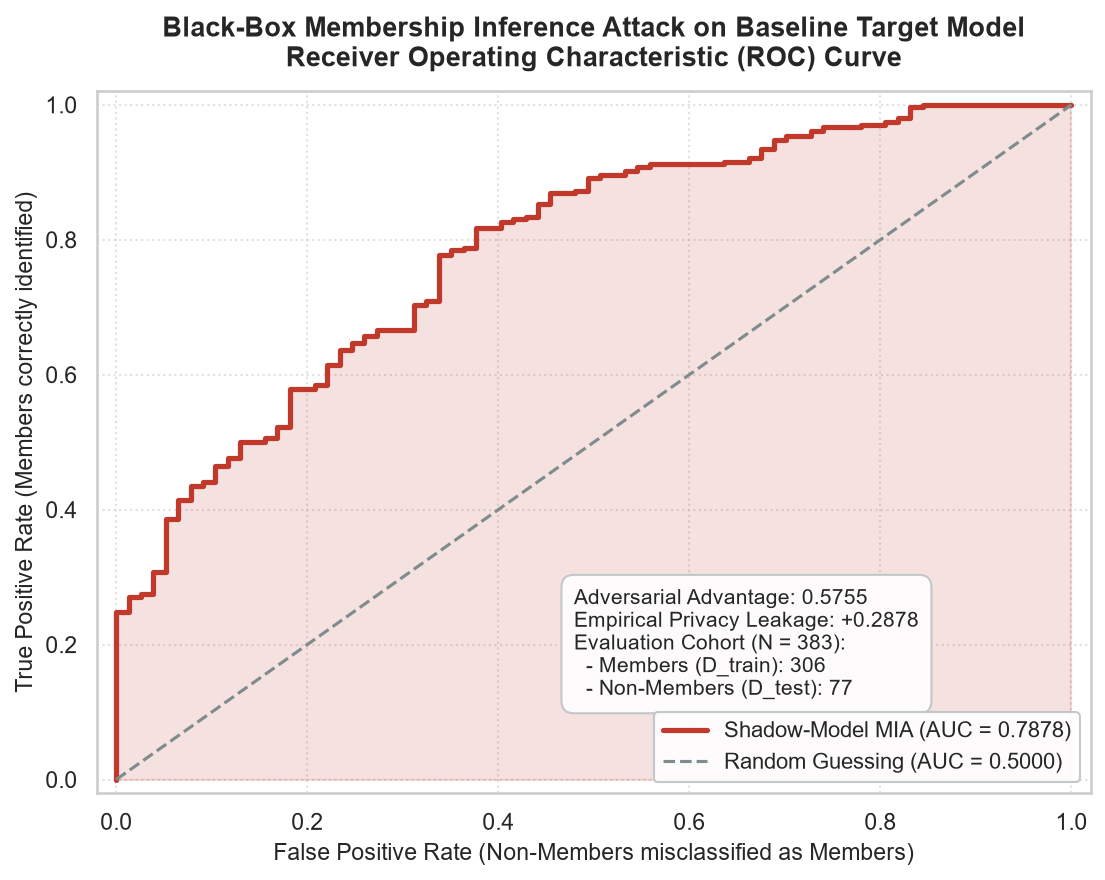

In [5]:
fpr, tpr, _ = roc_curve(eval_results["y_eval_true"], eval_results["y_eval_scores"])

fig, ax = plt.subplots(figsize=(7.5, 6))
ax.plot(fpr, tpr, color="#c0392b", linewidth=2.5, label=f"Shadow-Model MIA (AUC = {eval_results['roc_auc']:.4f})")
ax.fill_between(fpr, tpr, alpha=0.15, color="#c0392b")
ax.plot([0, 1], [0, 1], color="#7f8c8d", linestyle="--", linewidth=1.5, label="Random Guessing (AUC = 0.5000)")

ax.annotate(
    f"Adversarial Advantage: {eval_results['advantage']:.4f}\n" \
    f"Empirical Privacy Leakage: +{eval_results['privacy_leakage']:.4f}\n" \
    f"Evaluation Cohort (N = 383):\n" \
    f"  - Members (D_train): {eval_results['n_members']}\n" \
    f"  - Non-Members (D_test): {eval_results['n_non_members']}",
    xy=(0.48, 0.14),
    xycoords="axes fraction",
    fontsize=10,
    bbox=dict(boxstyle="round,pad=0.6", facecolor="white", edgecolor="#bdc3c7", alpha=0.9)
)

ax.set_xlim([-0.02, 1.02])
ax.set_ylim([-0.02, 1.02])
ax.set_xlabel("False Positive Rate (Non-Members misclassified as Members)", fontsize=11)
ax.set_ylabel("True Positive Rate (Members correctly identified)", fontsize=11)
ax.set_title("Black-Box Membership Inference Attack on Baseline Target Model\nReceiver Operating Characteristic (ROC) Curve", fontsize=13, fontweight="bold", pad=12)
ax.legend(loc="lower right", frameon=True, framealpha=0.9, edgecolor="#bdc3c7", fontsize=10.5)
ax.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

### Figure 2: Score Density Distribution (Members vs. Non-Members)
Shows how the predicted membership probabilities $P(\text{Member} \mid x)$ are distributed between training set patients ($D_{\text{train}}$) and unseen test patients ($D_{\text{test}}$).

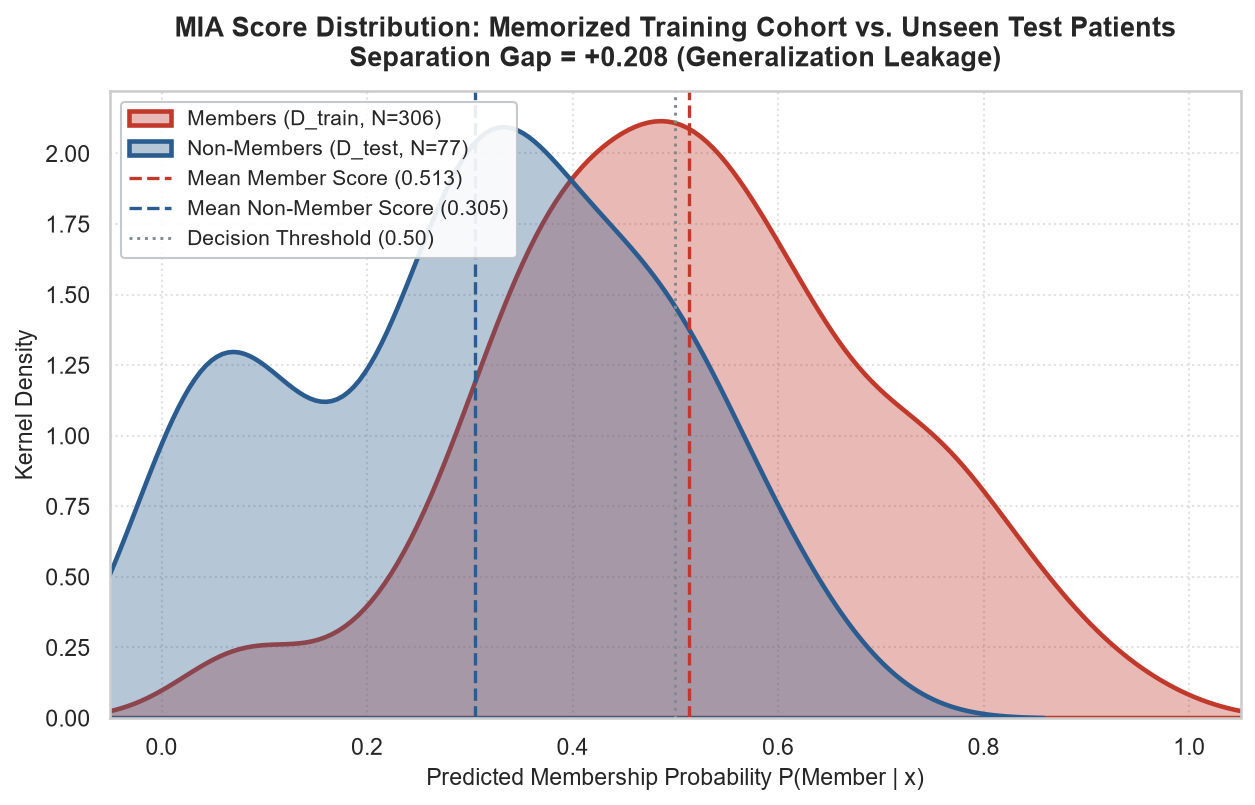

In [6]:
scores_mem = eval_results["scores_members"]
scores_non = eval_results["scores_non_members"]
mean_mem = np.mean(scores_mem)
mean_non = np.mean(scores_non)

fig, ax = plt.subplots(figsize=(8.5, 5.5))
sns.kdeplot(scores_mem, ax=ax, color="#c0392b", fill=True, alpha=0.35, linewidth=2.2, label=f"Members (D_train, N={len(scores_mem)})")
sns.kdeplot(scores_non, ax=ax, color="#2b5c8f", fill=True, alpha=0.35, linewidth=2.2, label=f"Non-Members (D_test, N={len(scores_non)})")

ax.axvline(mean_mem, color="#c0392b", linestyle="--", linewidth=1.6, label=f"Mean Member Score ({mean_mem:.3f})")
ax.axvline(mean_non, color="#2b5c8f", linestyle="--", linewidth=1.6, label=f"Mean Non-Member Score ({mean_non:.3f})")
ax.axvline(0.5, color="#7f8c8d", linestyle=":", linewidth=1.4, label="Decision Threshold (0.50)")

ax.set_xlim([-0.05, 1.05])
ax.set_xlabel("Predicted Membership Probability P(Member | x)", fontsize=11)
ax.set_ylabel("Kernel Density", fontsize=11)
ax.set_title(
    f"MIA Score Distribution: Memorized Training Cohort vs. Unseen Test Patients\n" \
    f"Separation Gap = {mean_mem - mean_non:+.3f} (Generalization Leakage)",
    fontsize=13,
    fontweight="bold",
    pad=12
)
ax.legend(loc="upper left", frameon=True, framealpha=0.9, edgecolor="#bdc3c7", fontsize=10)
ax.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

## 🔬 6. Scientific Discussion & Thesis Takeaways

### Key Quantitative Findings:
1. **High Adversarial Vulnerability:** The attack achieved **$\text{ROC-AUC} = 0.7878$** and **$\text{PR-AUC} = 0.9351$**, substantially outperforming random guessing ($\text{AUC} = 0.5000$).
2. **Remarkable Precision ($92.26\%$):** When the adversary predicts that a patient was part of the study ($P \ge 0.5$), they are correct **$92.26\%$ of the time**. In clinical genomics, this level of precision allows an attacker to re-identify patients with near certainty.
3. **Empirical Concordance with the Generalization Gap:**  
   $$\Delta_{\text{gen}} = 0.2741 \quad \longleftrightarrow \quad \Delta_{\text{leak}} = \text{AUC}_{\text{attack}} - 0.5 = 0.2878$$
   This empirical alignment directly validates the theoretical hypothesis: the $0.2741$ generalization gap observed in Phase 5 is almost entirely converted into privacy leakage by the shadow-model attack.
4. **Score Distribution Shift:** Members have a mean inferred score of $0.5134$ while non-members have a mean of $0.3053$, representing a significant $+0.2081$ probability shift.

### Paving the Way for Phase 7 (Differential Privacy):
Because the unmitigated baseline model is demonstrably insecure against membership inference attacks, clinical deployment of genomic machine learning models requires formal privacy guarantees. In **Phase 7**, we will design and benchmark **Differentially Private (DP)** training algorithms (e.g. DP-Random Forests and DP-SGD) to mathematically bound this privacy leakage.